<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/4_6_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
!apt-get install libopencv-dev -y > /dev/null 2>&1

!g++ -o odev5 odev5.cpp `pkg-config --cflags --libs opencv4` -pthread

!./odev5

cc1plus: fatal error: odev5.cpp: No such file or directory
compilation terminated.
/bin/bash: line 1: ./odev5: No such file or directory


In [36]:
%%writefile log_7x7.cpp
#include <opencv2/opencv.hpp>
#include <iostream>

using namespace cv;
using namespace std;

int main(int argc, char** argv) {
    if (argc != 2) {
        cout << "Kullanım: ./log_program <test>" << endl;
        return -1;
    }

    // 1. Görüntüyü gri tonlamalı olarak oku
    Mat image = imread(argv[1], IMREAD_GRAYSCALE);
    if (image.empty()) {
        cout << "HATA: Görüntü okunamadı! Lütfen dosya adını kontrol edin." << endl;
        return -1;
    }

    // 2. 7x7 Laplacian of Gaussian (LoG) Filtresi
    // Adım 2: 7x7 Gauss filtresi ile güçlü yumuşatma
    Mat blurred_image;
    GaussianBlur(image, blurred_image, Size(7, 7), 1.5, 1.5);
    // Not: Sigma değeri 1.5 olarak seçilmiştir. 7x7 kernel için uygundur.

    // Adım 2B: Laplacian filtresini uygula
    Mat log_result, abs_log;
    Laplacian(blurred_image, log_result, CV_32F, 3);

    // Görüntülenebilir 8-bit formata çevirdik
    convertScaleAbs(log_result, abs_log);

    // 3. Karşılaştırma için Gauss uygulanmamış salt Laplacian
    Mat pure_laplacian_result, abs_pure_laplacian;
    Laplacian(image, pure_laplacian_result, CV_32F, 3);
    convertScaleAbs(pure_laplacian_result, abs_pure_laplacian);

    // 4. Sonuçları kaydet
    imwrite("log_7x7_sonuc.jpg", abs_log);
    imwrite("pure_laplacian_sonuc.jpg", abs_pure_laplacian);

    cout << "BAŞARILI: 7x7 LoG ve Salt Laplacian uygulandı, dosyalar kaydedildi!" << endl;
    return 0;
}

Overwriting log_7x7.cpp


In [37]:
# OpenCV kütüphanelerini kurduk
!apt-get -q -y install libopencv-dev

# Kodu derle
!g++ log_7x7.cpp -o log_program `pkg-config --cflags --libs opencv4`

# Programı çalıştır
!./log_program "test"

Reading package lists...
Building dependency tree...
Reading state information...
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
BAŞARILI: 7x7 LoG ve Salt Laplacian uygulandı, dosyalar kaydedildi!


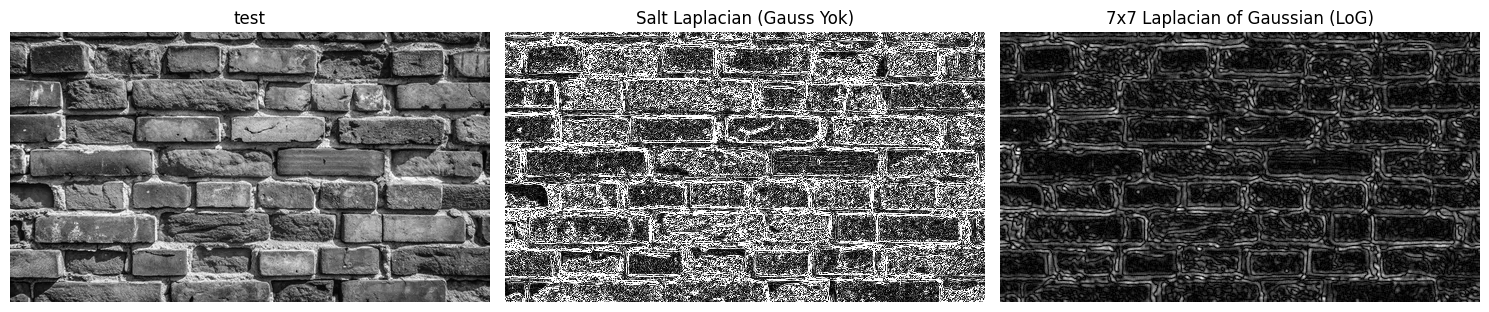

In [40]:
import cv2
import matplotlib.pyplot as plt
import os

# Görüntüleri oku
img_path = 'test'
log_path = 'log_7x7_sonuc.jpg'
pure_lap_path = 'pure_laplacian_sonuc.jpg'

if os.path.exists(img_path) and os.path.exists(log_path):
    orijinal = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    log_7x7 = cv2.imread(log_path, cv2.IMREAD_GRAYSCALE)
    pure_lap = cv2.imread(pure_lap_path, cv2.IMREAD_GRAYSCALE)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(orijinal, cmap='gray')
    plt.title('test')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(pure_lap, cmap='gray')
    plt.title('Salt Laplacian (Gauss Yok)')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(log_7x7, cmap='gray')
    plt.title('7x7 Laplacian of Gaussian (LoG)')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("HATA: Dosyalar bulunamadı.")

In [39]:
# Kenar Tespiti Analizi: 7x7 Laplacian of Gaussian (LoG) vs Diğer Filtreler

##Bu çalışmada, ikinci derece türev tabanlı kenar tespiti filtrelerinden Laplacian of Gaussian (LoG) operatörünün 7x7 pencere boyutundaki performansı, önceden yumuşatılmamış (salt) Laplacian ve birinci derece türev (Sobel/Prewitt) filtreleriyle kıyaslanmıştır.

## 1. LoG (Laplacian of Gaussian) Çalışma Mantığı
#Laplacian filtresi, doğası gereği gürültüye (noise) karşı son derece hassastır. Görüntüdeki en ufak bir pürüz, ikinci derece türevde büyük bir kenar değişimi olarak algılanır ve sahte kenarlara (beyaz karıncalanmalar) neden olur. Bunu önlemek için Laplacian uygulanmadan önce görüntüye Gaussian Blur (Gauss Yumuşatması) uygulanır. Bu ikili birleşik işleme **LoG (Marr-Hildreth Edge Detector)** adı verilir.

## 2. 7x7 Kernel Etkisi ve Karşılaştırma Sonuçları

##*   **Salt Laplacian (Gauss Ön-İşlemsiz):** Gauss uygulanmadan doğrudan Laplacian filtresi geçirildiğinde, sonuç neredeyse tamamen gürültüden ibaret olmuştur. Gerçek nesne sınırları (tuğlalar), sahte kenarlar arasında kaybolmuştur.
##*   **7x7 LoG Performansı:** 7x7'lik oldukça geniş bir Gauss çekirdeği (sigma ≈ 1.5) ile ön yumuşatma yapıldığında, yüksek frekanslı tüm gürültüler (kumlanma, doku detayları) silinmiştir. Ardından Laplacian uygulandığında, yalnızca **çok belirgin, ana hatları çizen, keskin ve sürekli kenarlar** tespit edilmiştir. İnce detaylar kaybolurken genel yapı (makro ölçekteki şekiller) ön plana çıkmıştır.
##  **Sobel/Prewitt (1. Derece) ile Kıyaslama:** Sobel ve Prewitt, kenarları belirli yönlerde (X veya Y) daha kalın ve yumuşak geçişlerle bulurken; 7x7 LoG, yönden bağımsız (izotropik) olarak nesnelerin sınırlarını "sıfır geçiş" (zero-crossing) noktalarıyla tek piksellik, ince ve kapalı konturlar (çizgiler) halinde bulma eğilimindedir.
## Sonuç
##Güçlü gürültü içeren görüntülerde veya sadece ana hatların çıkarılması gereken durumlarda (geniş ölçekli detayların yok edilmesi), geniş pencereli (7x7) bir Gauss ile desteklenen Laplacian (LoG) filtresi, geleneksel yöntemlere göre çok daha güvenilir ve pürüzsüz bir kenar haritası üretir.